# DBSCAN Clustering with SDSS Astronomical Data
## Can we find groups — and unusual objects — without choosing the number of clusters?

In the previous clustering notebook, we used **K-means**.

K-means required us to choose the number of clusters in advance. For example:

`n_clusters = 3`

Now we will try a different unsupervised machine-learning method:

# DBSCAN

**DBSCAN** stands for **Density-Based Spatial Clustering of Applications with Noise**.

Rather than asking us how many clusters to find, DBSCAN looks for **dense regions of data**.

This gives DBSCAN an interesting additional ability:

> It can identify objects that do not belong to any dense group.

These objects are labelled **noise**.

In astronomy, unusual or isolated objects can be particularly interesting, so this is a useful idea to explore.

### What you will learn

1. Load the same SDSS catalogue
2. Clean the photometry
3. Calculate astronomical colours
4. Scale the features
5. Understand density-based clustering
6. Run DBSCAN
7. Identify clusters and noise
8. Compare the discovered groups with known SDSS classes
9. Explore `eps` and `min_samples`

# 1. Import packages

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

### Missing a package?

Most Python installations used for this class should already contain the packages we need.

If you receive a `ModuleNotFoundError`, run the cell below once and then rerun the imports.

In [5]:
# Run this ONLY if a package is missing
# %pip install pandas numpy matplotlib scikit-learn

# 2. Load the same SDSS catalogue

We will use the same file as the decision-tree and K-means notebooks:

`sdss_decision_tree.csv`

Put it in the same folder as this notebook.

In [37]:
DATA_FILE = Path("sdss_5000_decision_tree.csv")

data = pd.read_csv(DATA_FILE)

print("Number of objects:", len(data))
print()
print("Columns:")
print(data.columns.tolist())

display(data.head())

Number of objects: 15000

Columns:
['ra', 'dec', 'u', 'g', 'r', 'i', 'z', 'redshift', 'class']


,ra,dec,u,g,r,i,z,redshift,class
0,145.28112,-0.330472,19.36548,18.94647,19.04925,19.21883,19.35806,0.000111,STAR
1,145.28412,0.706299,20.36442,18.21354,17.38881,17.11562,17.32000,0.000178,STAR
2,145.29280,0.376335,19.31302,18.13527,17.67289,17.49996,17.44187,0.000213,STAR
3,145.26257,0.310931,24.85999,20.76403,19.18368,17.93489,17.28289,0.000066,STAR
4,145.73040,1.164938,18.32052,17.01957,16.47373,16.26664,16.14915,0.000286,STAR


# 3. Clean the photometry

Some catalogue entries can contain placeholder or unreliable magnitude values.

For this exercise, we will keep objects where **all five SDSS magnitudes** are between 10 and 30.

The `&` symbol means **AND**, so an object must satisfy every condition to remain in the sample.

In [38]:
before = len(data)

good_data = (
    data["u"].between(10, 30) &
    data["g"].between(10, 30) &
    data["r"].between(10, 30) &
    data["i"].between(10, 30) &
    data["z"].between(10, 30)
)

data = data[good_data].copy()

after = len(data)

print("Objects before cleaning:", before)
print("Objects after cleaning:", after)
print("Objects removed:", before - after)

Objects before cleaning: 15000
Objects after cleaning: 14982
Objects removed: 18


# 4. Calculate astronomical colours

As before, we will use differences between neighbouring SDSS magnitudes:

- `u-g`
- `g-r`
- `r-i`
- `i-z`

These colours describe the relative brightness of an object at different wavelengths and therefore contain information about the shape of its spectrum.

In [39]:
data["u-g"] = data["u"] - data["g"]
data["g-r"] = data["g"] - data["r"]
data["r-i"] = data["r"] - data["i"]
data["i-z"] = data["i"] - data["z"]

display(data[["u-g", "g-r", "r-i", "i-z", "class"]].head())

,u-g,g-r,r-i,i-z,class
0,0.41901,-0.10278,-0.16958,-0.13923,STAR
1,2.15088,0.82473,0.27319,-0.20438,STAR
2,1.17775,0.46238,0.17293,0.05809,STAR
3,4.09596,1.58035,1.24879,0.65200,STAR
4,1.30095,0.54584,0.20709,0.11749,STAR


# 5. Look at the data before clustering

For now, hide the known STAR, GALAXY and QSO labels.

Can you see regions where the points are particularly dense?

Can you see objects that appear isolated from most of the sample?

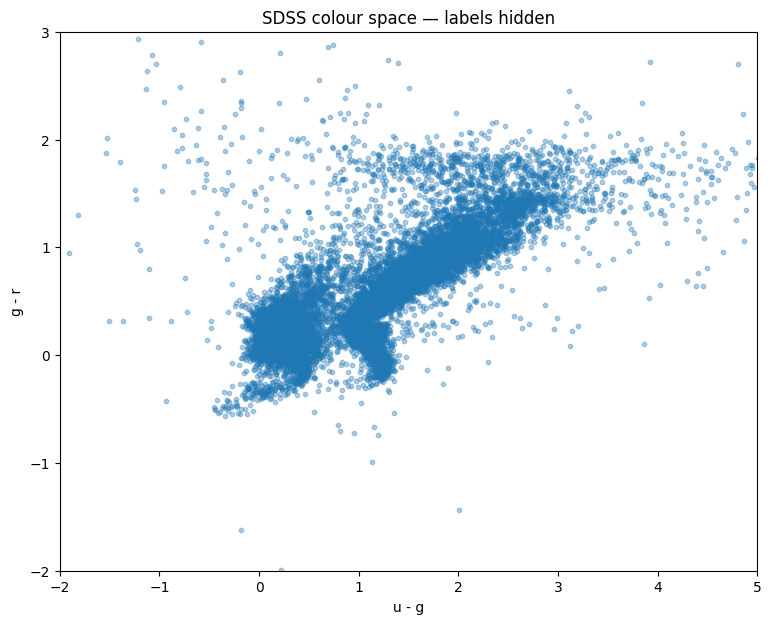

In [40]:
plt.figure(figsize=(9, 7))

plt.scatter(
    data["u-g"],
    data["g-r"],
    s=10,
    alpha=0.35
)

plt.xlabel("u - g")
plt.ylabel("g - r")
plt.title("SDSS colour space — labels hidden")
plt.xlim(-2, 5)
plt.ylim(-2, 3)

plt.show()

# 6. Choose and scale our features

DBSCAN uses distances between objects, so scaling is important.

We will use the same four colours as the K-means notebook.

In [41]:
features = ["u-g", "g-r", "r-i", "i-z", "u", "g", "r", "i", "z", "redshift"]

X = data[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-0.82524294 -1.23854703 -1.07980105 -0.86079393 -0.3031136   0.18142984
   0.69835284  1.10285413  1.31848624 -0.65175696]
 [ 1.04477951  0.37399069 -0.13408497 -1.02426624  0.30265005 -0.32145727
  -0.48873751 -0.46189692 -0.15358372 -0.65165624]
 [-0.00597773 -0.25597884 -0.34823113 -0.36568484 -0.33492568 -0.37516087
  -0.28564157 -0.17595476 -0.06555827 -0.65160399]
 [ 3.14501986  1.68768623  1.9497071   1.1245353   3.02879263  1.42851687
   0.79446023  0.14762547 -0.1803879  -0.65182485]
 [ 0.12705002 -0.11087809 -0.2752685  -0.21664025 -0.93678407 -1.14067892
  -1.14295124 -1.09352304 -0.99927674 -0.65149521]]


# 7. How does DBSCAN work?

DBSCAN looks at the **local density** around each point.

It has two especially important settings.

### `eps`

`eps` controls how close two points need to be before DBSCAN considers them neighbours.

You can imagine drawing a small circle around every point.

A **smaller `eps`** means a smaller neighbourhood.

A **larger `eps`** means a larger neighbourhood.

### `min_samples`

`min_samples` controls how many nearby points are needed before an area is considered dense.

For example:

`min_samples = 10`

means DBSCAN wants a point to have enough nearby neighbours before treating that region as part of a cluster.

Unlike K-means, we do **not** tell DBSCAN how many clusters to create.

# 8. Run DBSCAN

We will start with:

`eps = 0.3`

and:

`min_samples = 10`

These are starting values rather than universal correct answers.

One of the important parts of using DBSCAN is investigating how these settings affect the result.

In [70]:
dbscan = DBSCAN(
    eps=0.4,
    min_samples=30
)

clusters = dbscan.fit_predict(X_scaled)

data["cluster"] = clusters

# 9. How many groups did DBSCAN find?

DBSCAN uses ordinary numbers for clusters:

`0, 1, 2, 3...`

But it reserves one special value:

`-1`

An object assigned to **cluster -1** is considered **noise**.

That means DBSCAN did not think the object belonged to a sufficiently dense region of the feature space.

In [71]:
print("Objects in each DBSCAN group:")
print(data["cluster"].value_counts().sort_index())

cluster_labels = set(data["cluster"])

n_clusters = len(cluster_labels - {-1})
n_noise = (data["cluster"] == -1).sum()

print()
print("Number of clusters:", n_clusters)
print("Number of noise objects:", n_noise)
print(f"Noise fraction: {100*n_noise/len(data):.1f}%")

Objects in each DBSCAN group:
cluster
-1    4875
 0    7396
 1      24
 2      42
 3      17
 4    2598
 5      30
Name: count, dtype: int64

Number of clusters: 6
Number of noise objects: 4875
Noise fraction: 32.5%


# 10. Plot the DBSCAN result

Let's look at the groups DBSCAN found in `u-g` versus `g-r` colour space.

Remember that DBSCAN actually used **all four colours** when calculating its clusters, even though we can only easily display two dimensions at once.

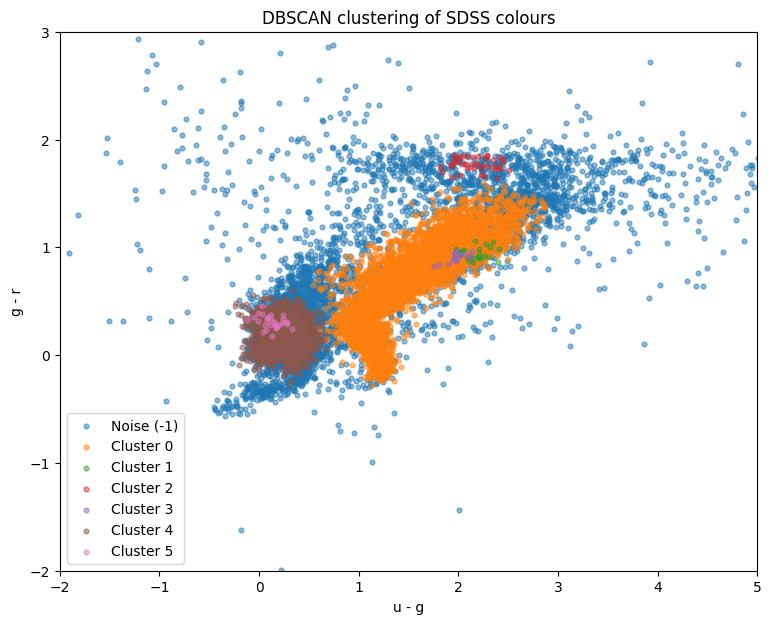

In [72]:
plt.figure(figsize=(9, 7))

for cluster in sorted(data["cluster"].unique()):

    subset = data[data["cluster"] == cluster]

    if cluster == -1:
        label = "Noise (-1)"
    else:
        label = f"Cluster {cluster}"

    plt.scatter(
        subset["u-g"],
        subset["g-r"],
        s=12,
        alpha=0.5,
        label=label
    )

plt.xlabel("u - g")
plt.ylabel("g - r")
plt.title("DBSCAN clustering of SDSS colours")
plt.xlim(-2, 5)
plt.ylim(-2, 3)
plt.legend()

plt.show()

# 11. Reveal the known astronomical classes

DBSCAN has not used the `class` column.

Now we can reveal the spectroscopic classifications and compare them with the structures DBSCAN discovered.

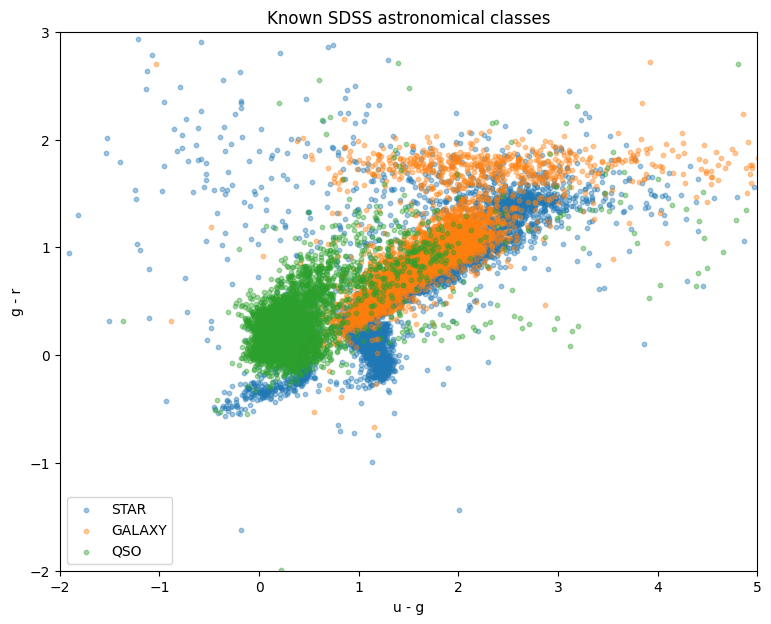

In [60]:
plt.figure(figsize=(9, 7))

for object_class in ["STAR", "GALAXY", "QSO"]:

    subset = data[data["class"] == object_class]

    plt.scatter(
        subset["u-g"],
        subset["g-r"],
        s=10,
        alpha=0.4,
        label=object_class
    )

plt.xlabel("u - g")
plt.ylabel("g - r")
plt.title("Known SDSS astronomical classes")
plt.xlim(-2, 5)
plt.ylim(-2, 3)
plt.legend()

plt.show()

# 12. Compare DBSCAN groups with the real classes

The rows below are the groups discovered by DBSCAN.

The columns are the known SDSS spectroscopic classifications.

Again, the class labels were **not used by DBSCAN**.

In [46]:
comparison = pd.crosstab(
    data["cluster"],
    data["class"]
)

comparison

class,GALAXY,QSO,STAR
cluster,,,
-1,1006,3282,2438
0,3968,147,2558
1,19,1,0
2,0,1485,0
3,0,35,0
4,0,43,0


In [47]:
comparison_percent = pd.crosstab(
    data["cluster"],
    data["class"],
    normalize="index"
) * 100

comparison_percent.round(1)

class,GALAXY,QSO,STAR
cluster,,,
-1,15.0,48.8,36.2
0,59.5,2.2,38.3
1,95.0,5.0,0.0
2,0.0,100.0,0.0
3,0.0,100.0,0.0
4,0.0,100.0,0.0


# 13. Investigate the noise

This is one of the most interesting differences between DBSCAN and K-means.

K-means assigns **every object** to a cluster.

DBSCAN does not have to.

Objects that do not sit inside a sufficiently dense region are labelled:

`cluster = -1`

Let's inspect them.

In [48]:
noise = data[data["cluster"] == -1]

print("Number of noise objects:", len(noise))
print()
print("Known classes among the noise:")
print(noise["class"].value_counts())

display(
    noise[
        ["u-g", "g-r", "r-i", "i-z", "class"]
    ].head(20)
)

Number of noise objects: 6726

Known classes among the noise:
class
QSO       3282
STAR      2438
GALAXY    1006
Name: count, dtype: int64


,u-g,g-r,r-i,i-z,class
0,0.41901,-0.10278,-0.16958,-0.13923,STAR
1,2.15088,0.82473,0.27319,-0.20438,STAR
3,4.09596,1.58035,1.24879,0.65200,STAR
7,1.33098,1.52953,1.29850,0.71839,STAR
10,1.66934,1.37863,1.30754,0.70842,STAR
16,1.11446,0.18369,0.03754,-0.06433,STAR
21,2.58230,1.06867,0.39160,0.21176,STAR
24,0.17017,-0.29816,-0.23754,-0.57570,STAR
25,1.25696,-0.04944,-0.05695,-0.02587,STAR
26,2.84074,1.54182,0.79035,0.50019,STAR


# 14. Plot the noise separately

Are the noise objects sitting around the edges of the main populations?

Are some very far away from most other objects?

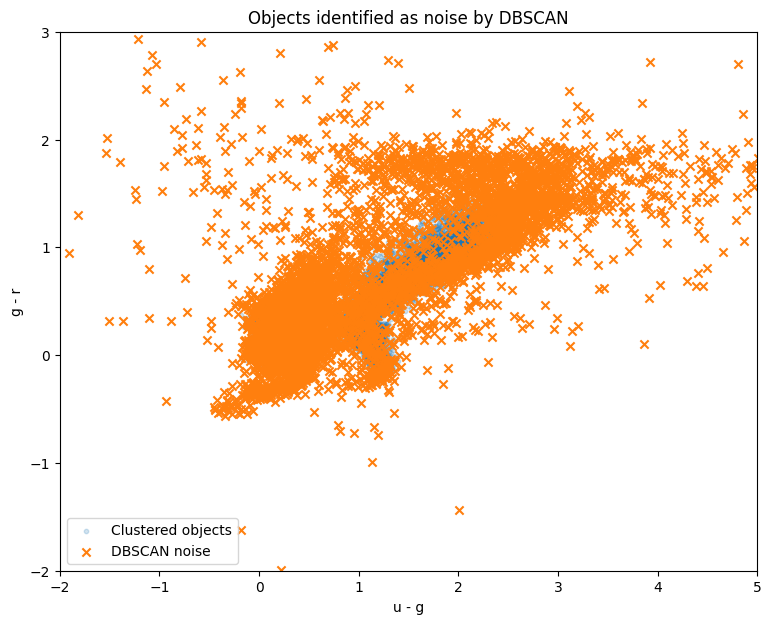

In [49]:
normal = data[data["cluster"] != -1]
noise = data[data["cluster"] == -1]

plt.figure(figsize=(9, 7))

plt.scatter(
    normal["u-g"],
    normal["g-r"],
    s=10,
    alpha=0.2,
    label="Clustered objects"
)

plt.scatter(
    noise["u-g"],
    noise["g-r"],
    s=35,
    marker="x",
    label="DBSCAN noise"
)

plt.xlabel("u - g")
plt.ylabel("g - r")
plt.title("Objects identified as noise by DBSCAN")
plt.xlim(-2, 5)
plt.ylim(-2, 3)
plt.legend()

plt.show()

# 15. What happens when we change `eps`?

`eps` controls the size of the neighbourhood DBSCAN considers around each point.

Let's try several values and count:

- how many clusters are produced
- how many objects are labelled noise

In [50]:
eps_values = [0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

results = []

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=10
    )

    labels = model.fit_predict(X_scaled)

    unique_labels = set(labels)

    n_clusters = len(unique_labels - {-1})
    n_noise = np.sum(labels == -1)

    results.append({
        "eps": eps,
        "clusters": n_clusters,
        "noise": n_noise
    })

results = pd.DataFrame(results)

results

,eps,clusters,noise
0,0.15,26,12022
1,0.20,25,9178
2,0.25,17,6861
3,0.30,21,5008
4,0.40,11,2716
5,0.50,3,1799


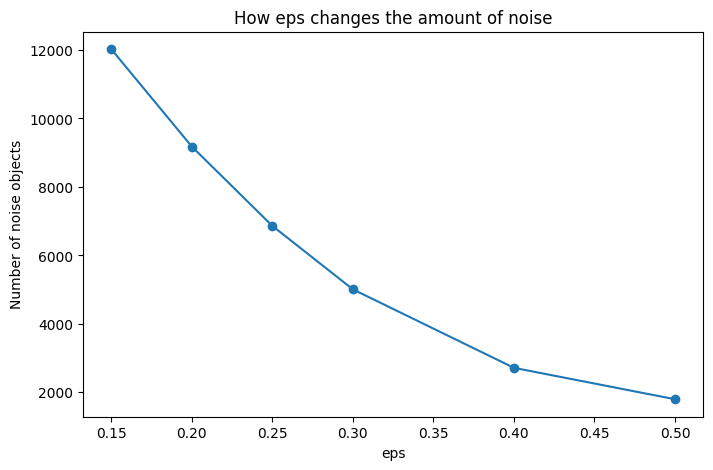

In [51]:
plt.figure(figsize=(8, 5))

plt.plot(
    results["eps"],
    results["noise"],
    marker="o"
)

plt.xlabel("eps")
plt.ylabel("Number of noise objects")
plt.title("How eps changes the amount of noise")

plt.show()

# 16. Compare K-means and DBSCAN

The two clustering methods make different assumptions.

### K-means

- You choose the number of clusters in advance.
- Every object must belong to a cluster.
- It works particularly naturally for compact groups around cluster centres.

### DBSCAN

- You do not specify the number of clusters.
- It searches for dense regions.
- Clusters can have more complicated shapes.
- Some objects can be labelled as noise.

Neither method is automatically better.

They are answering slightly different questions about the structure in the data.

# Your turn

## Exercise 1 — change `eps`

Try:

```python
eps=0.2
```

then:

```python
eps=0.4
eps=0.5
```

How do the number of clusters and noise objects change?

---

## Exercise 2 — change `min_samples`

Keep `eps` fixed and try:

```python
min_samples=5
```

then:

```python
min_samples=20
min_samples=30
```

What happens?

---

## Exercise 3 — investigate the noise

Look at:

```python
data[data["cluster"] == -1]
```

Which known astronomical class appears most often?

Are the noise objects necessarily mistakes or bad data?

Could an unusual astronomical object potentially appear as noise?

---

## Exercise 4 — use only two colours

Try:

```python
features = ["u-g", "g-r"]
```

Scale the features again and rerun DBSCAN.

Does the clustering become easier to interpret?

---

## Exercise 5 — compare with K-means

Compare this result with your K-means notebook.

Ask:

- Which method produces more interpretable groups?
- Which better resembles the known classes?
- What happens to unusual objects?
- Which method requires more choices from you before clustering?

# Take-home idea

DBSCAN is a **density-based unsupervised learning algorithm**.

Instead of being told how many clusters to find, it searches for regions where many objects are packed closely together.

Objects outside those dense regions can be labelled as **noise**.

This makes DBSCAN particularly interesting for exploratory astronomy because the objects that do not fit neatly into the main populations may deserve further investigation.

But there is an important warning:

> **Noise does not automatically mean discovery.**

An unusual point could represent an interesting astronomical object, but it could also be caused by measurement uncertainty, bad photometry, catalogue problems, or an inappropriate choice of DBSCAN parameters.

Machine learning can help us identify unusual objects.

Understanding **why** they are unusual still requires astronomy.